# LAB: Machine Learning - Supervised Models: Classification Models

![Machine Learning](https://user-images.githubusercontent.com/970858/63474771-d6734700-c469-11e9-83bb-9429da563909.png)


## Wine Quality Prediction

Introduction
In this project, we will walk through a comprehensive Machine Learning workflow using a wine quality dataset. Our goal is to build and compare different supervised classification models to predict wine quality based on several features such as acidity, alcohol level, and pH. We will explore and evaluate models including Logistic Regression, K-Nearest Neighbors, Decision Trees, Support Vector Machines, and Random Forest. Additionally, we will apply cross-validation techniques to optimize the model performance.

You will work with a dataset that includes various attributes of wines and their quality ratings. Your goal is to evaluate different classification models, assess their performance, and select the best model for predicting wine quality.

## Initial Setup
### Requirements
Start by forking the provided GitHub repository to your account and then clone it locally. This will be your workspace for completing the lab exercises.
- [Learn how to fork this repo](https://docs.github.com/en/get-started/exploring-projects-on-github/contributing-to-a-project)
- Clone this repo into your code/labs folder.

### Setup Instructions
To run the notebook and reproduce the results, follow these steps:
1. Clone the repository:
    ```bash
    git clone https://github.com/codeskills-ai/LAB-Machine-Learning-Supervised-Models-Classification-Models.git
    cd LAB-Machine-Learning-Supervised-Models-Classification-Models
    ```

2. Create a virtual environment and install the required packages:

    ```bash
    pip install -r requirements.txt
    ```

3. Start Jupyter Notebook:
   ```bash
   jupyter notebook
   ```

To test that everything is set up correctly, run the first cell in the notebook. This cell usually contains import statements and initial setup code. If it runs without errors, you are ready to start solving the exercises.

You can write and execute your code in the provided cells within the notebook. Any outputs, including print statements and visualizations, will be displayed directly in the notebook, making it easy to debug and verify your solutions.

## Workflow


### Iteration 1: Data Load

Load the Wine Quality dataset, which contains various attributes of wines and their quality ratings. Use Python libraries to load the dataset into a pandas DataFrame for further analysis.

- Import the necessary Python libraries: `pandas` and `sklearn.datasets`.
- Load the `load_wine` dataset, which includes data on wine features and quality.
- Display the first few rows of the dataset to understand its structure and the type of data it contains.

In [47]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine()
df = pd.DataFrame(data = wine.data, columns = wine.feature_names)
df['target'] = wine.target
print(df.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [48]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


**NOTE**: Remember import libraries.

### Iteration 2: Data Exploration

In this section, we will explore the dataset visually to understand the distribution of the target variable (`target`) and its relationship with other features.

- Import the necessary visualization libraries: `seaborn` and `matplotlib.pyplot`.
- Visualize the distribution of the target variable (`target`) using a histogram.
- Use a pairplot to generate scatter plots for some features (e.g., `alcohol`, `malic_acid`, `ash`) against the target variable (`target`).

**NOTE**: This initial inspection is crucial as it sets the stage for the next steps of data cleaning and visualization.

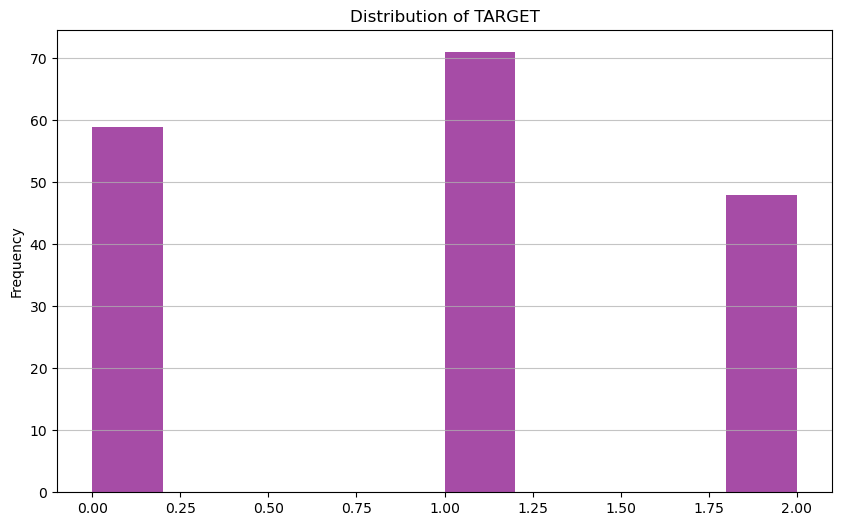

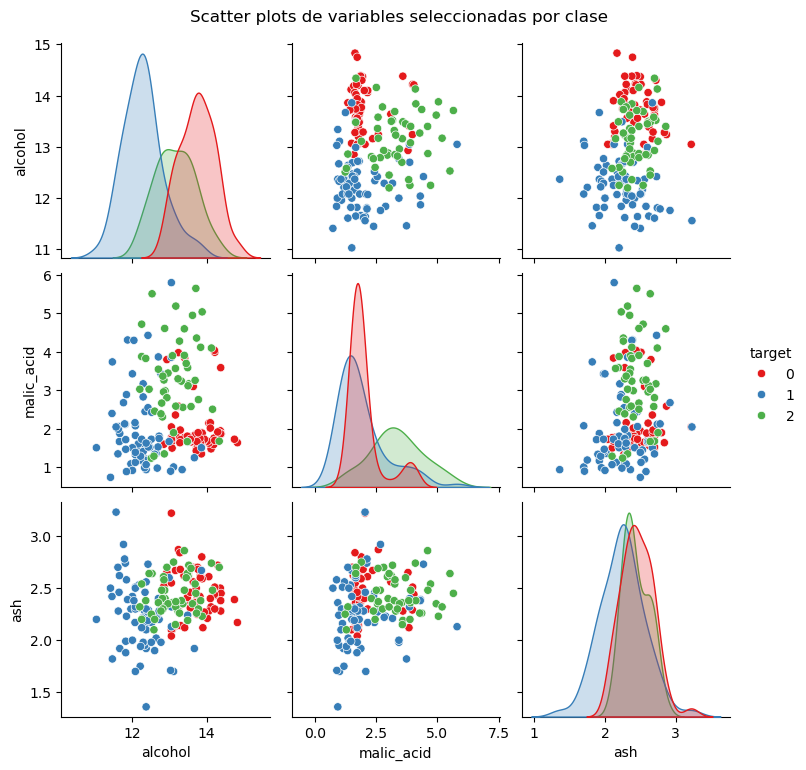

(178, 14)

In [51]:
import matplotlib.pyplot as plt
import seaborn as sn

plt.figure(figsize=(10, 6))
plt.hist(df['target'], bins=10, color='purple', alpha=0.7)
plt.title('Distribution of TARGET')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

# Seleccionar columnas a graficar
features = ['alcohol', 'malic_acid', 'ash', 'target']
df_subset = df[features]

# Crear pairplot con hue en 'target'
sn.pairplot(df_subset, hue='target', diag_kind='kde', palette='Set1')
plt.suptitle('Scatter plots de variables seleccionadas por clase', y=1.02)
plt.show()

df.shape

### Iteration 3: Feature Selection

- **Feature Selection**: Select relevant features from the dataset that will be used for model training. Features include chemical properties such as:
  - `alcohol`
  - `malic_acid`
  - `ash`
  - `alcalinity_of_ash`
  - `magnesium`
  - `total_phenols`
  - `flavanoids`
  - `nonflavanoid_phenols`
  - `proanthocyanins`
  - `color_intensity`
  - `hue`
  - `od280/od315_of_diluted_wines`
  - `proline`
  
- **Target Variable**: The target variable `target` indicates the quality class of the wine, categorized into three classes: 0, 1, or 2.

- **Calculate correlation matrix**: Calculate the correlation matrix of the selected characteristics to see how they are related to each other. Reason if any of the features should be removed to reduce the complexity of the model. 

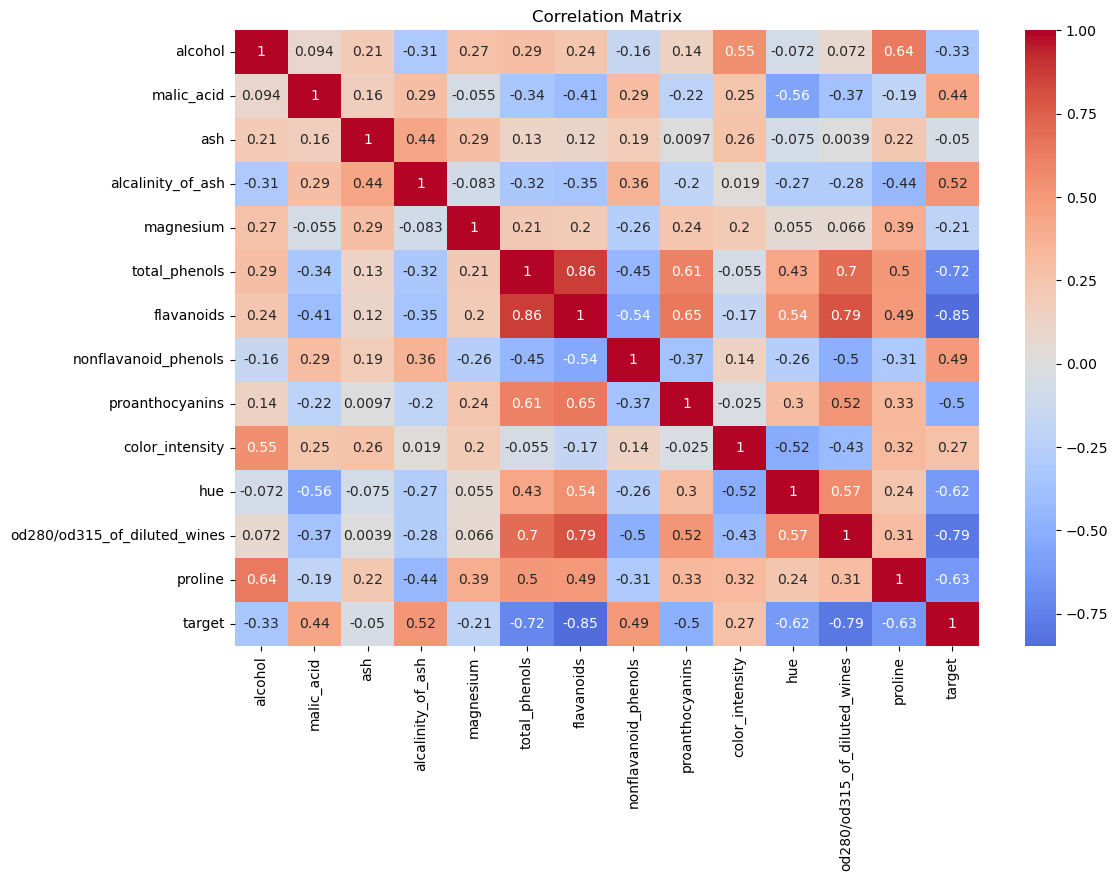

Features with correlation > 0.5:
alcalinity_of_ash               0.517859
total_phenols                  -0.719163
flavanoids                     -0.847498
hue                            -0.617369
od280/od315_of_diluted_wines   -0.788230
proline                        -0.633717
Name: target, dtype: float64


In [ ]:
# Correlation matrix
# Calcular la matriz de correlación
corr_matrix = df.corr()

# Visualizar la matriz de correlación con la target
plt.figure(figsize=(12, 8))
sn.heatmap(corr_matrix, annot=True, cmap='coolwarm', center = 0)
plt.title('Correlation Matrix')
plt.show()

# Seleccionar características con correlación > 0.5 
high_corr_features = corr_matrix['target'][corr_matrix['target'].abs() > 0.5].drop('target')
print("Features with correlation > 0.5:")
print(high_corr_features)


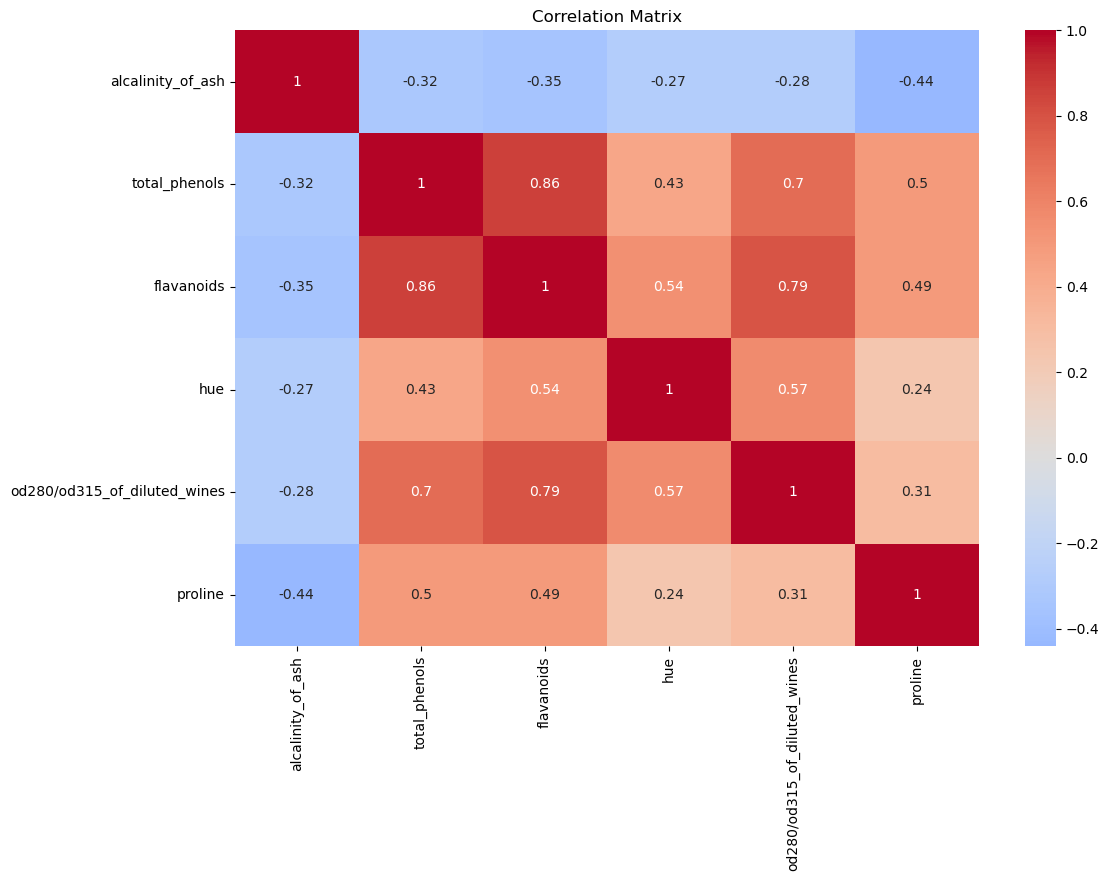

                        Feature        VIF
5                       proline   8.831483
0             alcalinity_of_ash  16.886945
3                           hue  24.632215
2                    flavanoids  25.839698
4  od280/od315_of_diluted_wines  40.382428
1                 total_phenols  53.651556


In [60]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

features = df[['alcalinity_of_ash', 'total_phenols',
                   'flavanoids','hue','od280/od315_of_diluted_wines','proline']]
corr_features = features.corr()

# Visualizar la matriz de correlación con la target
plt.figure(figsize=(12, 8))
sn.heatmap(corr_features, annot=True, cmap='coolwarm', center = 0)
plt.title('Correlation Matrix')
plt.show()


# Calculating VIF (Variance Inflation Factor) to check for multicollinearity
# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['Feature'] = features.columns
vif_data['VIF'] = [variance_inflation_factor(features.values, i) for i in range(features.shape[1])]

print(vif_data.sort_values(by='VIF'))


### Iteration 4: Data Splitting

- **Split the Data**: Split the dataset into training and testing sets using `train_test_split` from `sklearn.model_selection`. The split ensures that the model is trained on one portion of the data and tested on a separate portion to evaluate its performance.

### Iteration 5: Train and Evaluate Classification Models

Train and evaluate various classification models on the wine dataset to predict the quality class.

- **Logistic Regression**: Train and evaluate a Logistic Regression model.
- **K-Nearest Neighbors (K-NN)**: Train and evaluate a K-NN model.
- **Decision Tree**: Train and evaluate a Decision Tree model.
- **Support Vector Machine (SVM)**: Train and evaluate an SVM model.
- **Random Forest**: Train and evaluate a Random Forest model.

For each model calculate:

In [ ]:
# 1. Import the necessary libraries
...

In [ ]:
# 2. Split your data
...

In [ ]:
# 3. Calculate optimization parameters as optimal-k for KNN
...

In [ ]:
# 4. Initialize and train the model
...

In [ ]:
# 5. Make predictions and evaluate the model
...

### Iteration 6: Model Comparison

Compare the trained models in terms of accuracy. Use a bar chart to visualize the accuracy of each model to identify which one performs best.

In [ ]:
...

### Iteration 7: Cross-Validation

Apply cross-validation to each model to evaluate their mean accuracy and standard deviation. This step ensures the robustness of the models by testing them on different subsets of the data.

In [ ]:
...

### Iteration 8: Conclusions

Analyze and discuss which model is the most suitable for the wine dataset classification task based on the accuracy, cross-validation results, and overall model performance.

## Submission
Once you have completed your analysis and visualizations, push your Jupyter notebook to your forked GitHub repository. Ensure that your final submission includes narratives explaining your visualizations and insights.

```bash
$ git add .
$ git commit -m "done"
$ git push origin main
```

Then create a Pull Request!!

## Additional Resources

- [ ]()
- [ ](/)
- [ ]()
- [ ]().
- [ ]().

![happy_coding](https://user-images.githubusercontent.com/970858/63899010-c23fc480-c9ea-11e9-84a2-542907e42362.png)
